# Lake Water Quality from Sentinel-2: Chlorophyll-a and Algal Blooms (NDCI)

This notebook maps **chlorophyll-a** and **algal bloom** conditions in a lake from Sentinel-2 surface reflectance
(`COPERNICUS/S2_SR_HARMONIZED`) in Google Earth Engine:

| Index | Formula | Meaning |
|---|---|---|
| **NDCI** | (B5 − B4) / (B5 + B4) | Normalized Difference Chlorophyll Index (Mishra & Mishra 2012) |
| **Chl-a index** | B5 / B4 | Red-edge / red band ratio (as in the original script) |
| **Chl-a estimate** | 14.039 + 86.115·NDCI + 194.325·NDCI² (µg/L) | Empirical conversion (Mishra & Mishra 2012), approximate |
| **Bloom fraction** | share of water pixels with NDCI > threshold | Extent of high-chlorophyll water |

The default study area is the **a part of Chesapeake Bay (Lower James River)**, which has recurring summer cyanobacterial blooms.

**Outputs:** per-date water-quality table, monthly and yearly statistics, time series (as in the original chart),
seasonal comparison between years, and maps of mean NDCI and the peak bloom date.

> Ported from the original Earth Engine JavaScript (Code Editor) script.

## 1. Setup

Results of the Earth Engine steps are saved to `outputs/ndci/` as they are computed, so after a kernel restart
**Restart & Run All** loads finished work from disk instead of recomputing it.

In [1]:
import os, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
import matplotlib.patches as mpatches
import requests
from PIL import Image

In [2]:
import ee
ee.Authenticate(auth_mode="localhost")
ee.Initialize(project="add your GEE username here!")

C:\Users\moham\anaconda3\Lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.18) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


## 2. Parameters

In [3]:
# --- Output folders (new names, so the Lake Erie results are kept separately) ---
FIG_DIR, OUT_DIR = "figures/ndci_chesapeake", "outputs/ndci_chesapeake"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# --- Study area: lower James River estuary, Chesapeake Bay ---
BBOX = [-76.80, 36.85, -76.25, 37.25]
roi = ee.Geometry.Rectangle(BBOX)
ROI_NAME = "Lower James River (Chesapeake Bay)"

START, END   = "2023-01-01", "2025-01-01"
MAX_CLOUD    = 45
WATER_NDWI   = 0.1
BLOOM_NDCI   = 0.2
BLOOM_MONTHS = [6, 7, 8, 9]    # Chesapeake blooms peak June–September
MIN_COVERAGE = 0.30
SCALE        = 30              
BATCH        = 8
FORCE_RECOMPUTE = False

## 3. Sentinel-2 preprocessing

Compared with the original script, clouds, cloud shadows, cirrus and snow are removed using the Sentinel-2
scene classification (`SCL`), so cloud edges are not mistaken for chlorophyll. Water is still identified with
NDWI > 0.1 as in the original, and a permanent-water reference from the JRC Global Surface Water dataset is used to
measure how much of the lake is visible on each date. Images from the same day (several tiles) are mosaicked.

In [4]:
s2 = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterDate(START, END)
        .filterBounds(roi)
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", MAX_CLOUD)))

def prepare(img):
    b = img.select(["B2", "B3", "B4", "B5", "B8"]).multiply(0.0001)
    scl = img.select("SCL")
    clear = scl.neq(1).And(scl.neq(3)).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10)).And(scl.neq(11))
    water = b.normalizedDifference(["B3", "B8"]).gt(WATER_NDWI).And(clear)
    ndci = b.normalizedDifference(["B5", "B4"]).rename("ndci")
    ratio = b.select("B5").divide(b.select("B4")).rename("chl_ratio")
    chl = ndci.expression("14.039 + 86.115 * n + 194.325 * n * n", {"n": ndci}).max(0).rename("chl_a_ugL")
    bloom = ndci.gt(BLOOM_NDCI).rename("bloom")
    return (ee.Image.cat(ndci, ratio, chl, bloom).updateMask(water)
              .copyProperties(img, ["system:time_start"]))

indices = s2.map(prepare)
water_ref = (ee.Image("JRC/GSW1_4/GlobalSurfaceWater").select("occurrence").gte(50)
               .selfMask().clip(roi))          # permanent water (present ≥50% of the time)

times = s2.aggregate_array("system:time_start").getInfo()
dates = sorted(set(pd.to_datetime(times, unit="ms").normalize()))
print(f"Sentinel-2 images: {len(times)} | distinct dates: {len(dates)}")

Sentinel-2 images: 141 | distinct dates: 81


## 4. Lake-wide statistics for every date

For each date: the visible share of the lake (`coverage`), the mean and 90th percentile of each index over
water, and the bloom fraction. Progress is saved after every batch, so an interrupted run resumes where it stopped.

In [5]:
STATS_CSV = f"{OUT_DIR}/ndci_by_date.csv"
reduce_kw = dict(geometry=roi, scale=SCALE, maxPixels=1e13, tileScale=8)
reducer = ee.Reducer.mean().combine(ee.Reducer.percentile([90]), sharedInputs=True)

def date_stats(t):
    d0 = ee.Date(t)
    img = indices.filterDate(d0, d0.advance(1, "day")).mosaic().updateMask(water_ref)
    coverage = (img.select("ndci").mask().gt(0).unmask(0).rename("coverage").updateMask(water_ref)
                   .reduceRegion(ee.Reducer.mean(), **reduce_kw).get("coverage"))
    vals = img.reduceRegion(reducer, **reduce_kw)
    return ee.Feature(None, vals).set({"date": d0.format("YYYY-MM-dd"), "coverage": coverage})

def fetch_safely(batch):
    try:
        ms = [int(d.timestamp() * 1000) for d in batch]
        fc = ee.FeatureCollection(ee.List(ms).map(lambda t: date_stats(t)))
        return [f["properties"] for f in fc.getInfo()["features"]]
    except ee.EEException as e:
        if len(batch) == 1:
            print(f"  skipped {batch[0]:%Y-%m-%d} (will retry on next run): {str(e)[:80]}")
            return []
        return [r for d in batch for r in fetch_safely([d])]

saved = pd.read_csv(STATS_CSV) if os.path.exists(STATS_CSV) and not FORCE_RECOMPUTE else pd.DataFrame()
done = set(saved["date"]) if len(saved) else set()
todo = [d for d in dates if f"{d:%Y-%m-%d}" not in done]
print(f"{len(dates) - len(todo)} dates already done, {len(todo)} to process")

for i in range(0, len(todo), BATCH):
    rows = fetch_safely(todo[i:i + BATCH])
    saved = pd.concat([saved, pd.DataFrame(rows)], ignore_index=True)
    saved.to_csv(STATS_CSV, index=False)
    print(f"{min(i + BATCH, len(todo))}/{len(todo)} dates processed")

wq = (saved.assign(date=lambda d: pd.to_datetime(d["date"]))
           .drop_duplicates("date", keep="last").set_index("date").sort_index())
wq = wq.apply(pd.to_numeric, errors="coerce")
good = wq[(wq["coverage"] >= MIN_COVERAGE) & wq["ndci_mean"].notna()].copy()
print(f"Dates with ≥{MIN_COVERAGE:.0%} of the lake visible: {len(good)} of {len(wq)}")
good[["coverage", "ndci_mean", "ndci_p90", "chl_ratio_mean", "chl_a_ugL_mean", "bloom_mean"]].round(3).head()

16 dates already done, 65 to process
8/65 dates processed
16/65 dates processed
24/65 dates processed
32/65 dates processed
40/65 dates processed
48/65 dates processed
56/65 dates processed
64/65 dates processed
65/65 dates processed
Dates with ≥30% of the lake visible: 70 of 81


,coverage,ndci_mean,ndci_p90,chl_ratio_mean,chl_a_ugL_mean,bloom_mean
date,,,,,,
2023-01-15,0.978,-0.100,-0.020,0.824,8.195,0.001
2023-01-20,0.421,-0.175,-0.039,0.721,9.104,0.001
2023-02-04,0.936,-0.112,0.074,0.840,11.277,0.035
2023-02-14,0.982,-0.155,0.059,0.786,10.583,0.044
2023-02-19,0.708,-0.108,0.020,0.821,8.937,0.012


## 5. Monthly and yearly statistics

In [6]:
good["year"], good["month"] = good.index.year, good.index.month
cols = {"ndci_mean": "NDCI (mean)", "ndci_p90": "NDCI (90th pct.)", "chl_ratio_mean": "Chl-a index B5/B4",
        "chl_a_ugL_mean": "Chl-a estimate (µg/L)", "bloom_mean": "Bloom fraction"}

monthly = good.groupby(["year", "month"])[list(cols)].mean().rename(columns=cols)
monthly["Dates"] = good.groupby(["year", "month"]).size()
monthly.round(3).to_csv(f"{OUT_DIR}/ndci_monthly.csv")

def year_summary(g):
    season = g[g["month"].isin(BLOOM_MONTHS)]
    peak = season["ndci_p90"].idxmax() if len(season) else g["ndci_p90"].idxmax()
    return pd.Series({
        "Dates used": len(g),
        "Bloom-season dates": len(season),
        "Bloom-season mean NDCI": season["ndci_mean"].mean(),
        "Bloom-season mean chl-a (µg/L)": season["chl_a_ugL_mean"].mean(),
        "Bloom-season mean bloom fraction": season["bloom_mean"].mean(),
        f"Dates with >20% of lake NDCI > {BLOOM_NDCI}": int((g["bloom_mean"] > 0.2).sum()),
        "Peak date (highest NDCI p90)": f"{peak:%Y-%m-%d}",
        "Peak NDCI p90": g.loc[peak, "ndci_p90"],
        "Peak bloom fraction": g.loc[peak, "bloom_mean"],
    })

yearly = pd.DataFrame({y: year_summary(g) for y, g in good.groupby("year")})
yearly.to_csv(f"{OUT_DIR}/ndci_yearly_summary.csv")
peak_date = good["ndci_p90"].idxmax()
print(f"Overall peak date: {peak_date:%Y-%m-%d}")
yearly

Overall peak date: 2024-02-29


,2023,2024
Dates used,36,34
Bloom-season dates,11,12
Bloom-season mean NDCI,-0.015044,-0.017513
Bloom-season mean chl-a (µg/L),13.220358,13.047856
Bloom-season mean bloom fraction,0.003092,0.001771
Dates with >20% of lake NDCI > 0.2,0,0
Peak date (highest NDCI p90),2023-07-29,2024-07-23
Peak NDCI p90,0.050416,0.037921
Peak bloom fraction,0.002152,0.002184


## 6. Figures

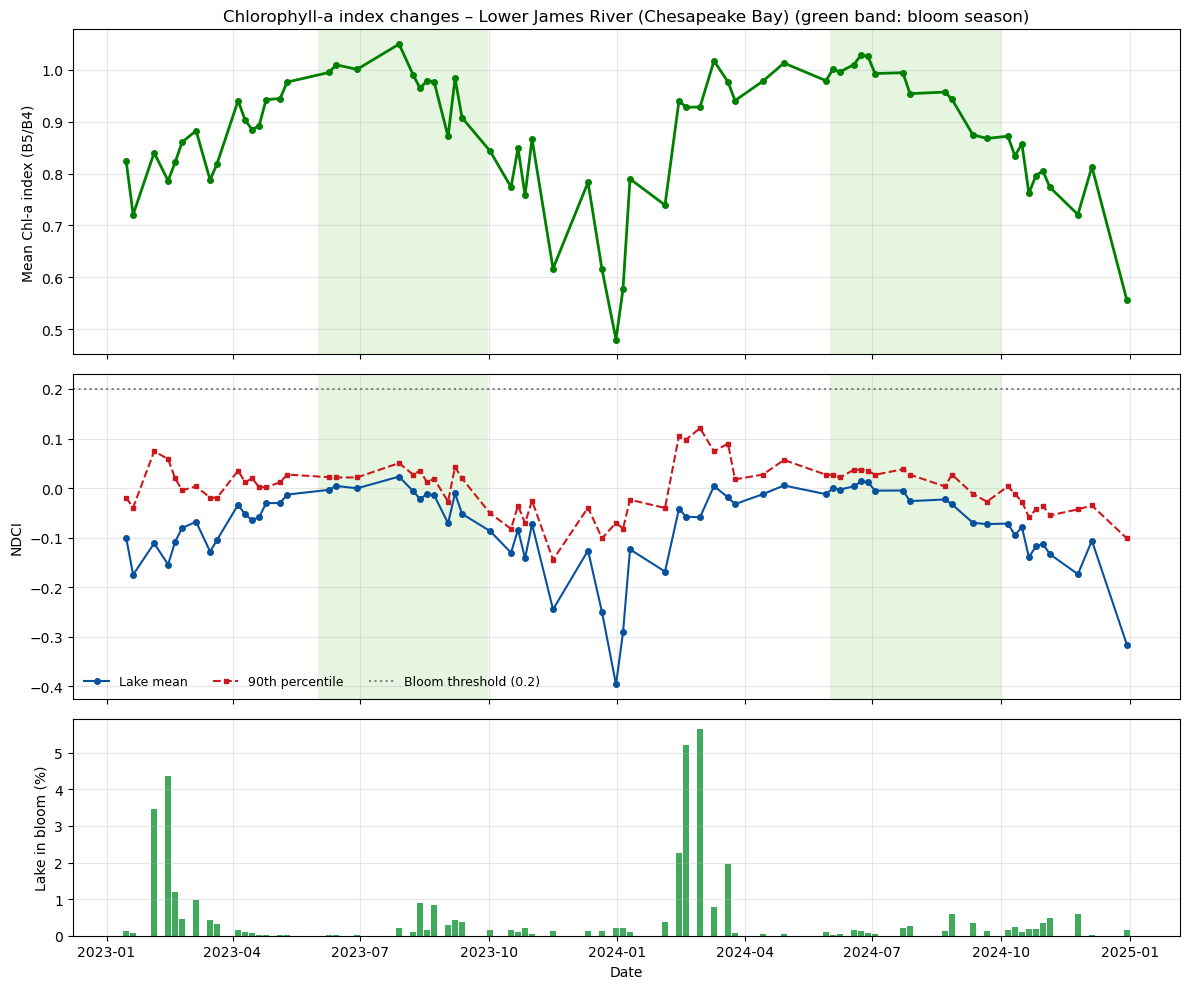

In [7]:
def shade_season(ax):
    for y in sorted(set(good.index.year)):
        ax.axvspan(pd.Timestamp(y, BLOOM_MONTHS[0], 1), pd.Timestamp(y, BLOOM_MONTHS[-1], 1) + pd.offsets.MonthEnd(1),
                   color="#e5f5e0", zorder=0)

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True, gridspec_kw={"height_ratios": [3, 3, 2]})
shade_season(axes[0])
axes[0].plot(good.index, good["chl_ratio_mean"], "o-", color="green", lw=2, ms=4)   # as in the original chart
axes[0].set(ylabel="Mean Chl-a index (B5/B4)",
            title=f"Chlorophyll-a index changes – {ROI_NAME} (green band: bloom season)")
shade_season(axes[1])
axes[1].plot(good.index, good["ndci_mean"], "o-", color="#08519c", ms=4, label="Lake mean")
axes[1].plot(good.index, good["ndci_p90"], "s--", color="#cb181d", ms=3, label="90th percentile")
axes[1].axhline(BLOOM_NDCI, color="gray", ls=":", label=f"Bloom threshold ({BLOOM_NDCI})")
axes[1].set_ylabel("NDCI"); axes[1].legend(frameon=False, fontsize=9, ncol=3)
axes[2].bar(good.index, 100 * good["bloom_mean"], width=4, color="#41ab5d")
axes[2].set(ylabel="Lake in bloom (%)", xlabel="Date")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/01_ndci_timeseries.png"); plt.show()

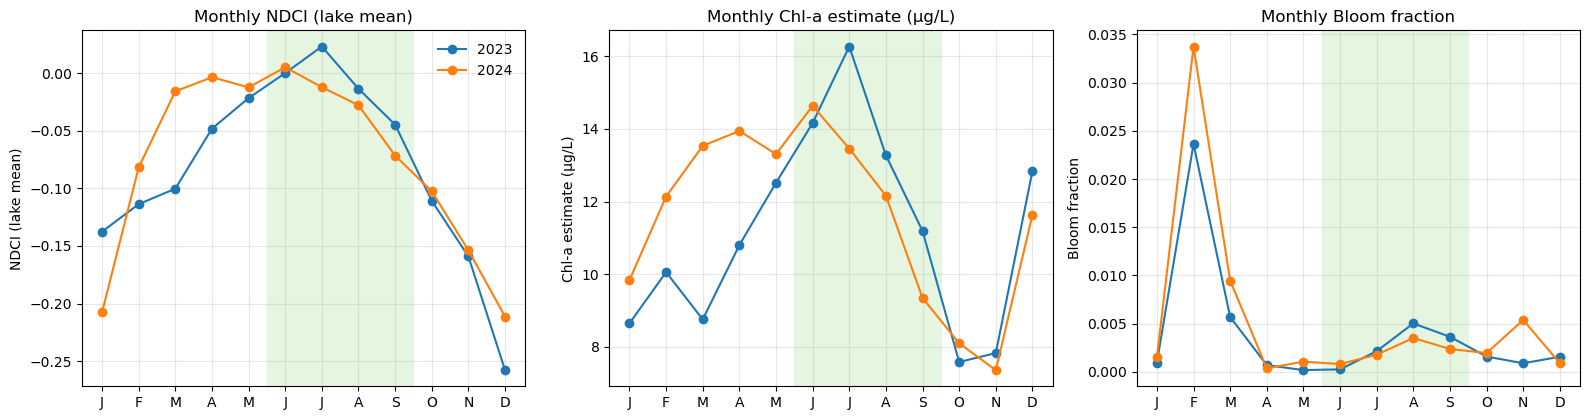

In [8]:
clim = good.groupby(["year", "month"])[["ndci_mean", "bloom_mean", "chl_a_ugL_mean"]].mean().reset_index()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharex=True)
for ax, col, label in zip(axes, ["ndci_mean", "chl_a_ugL_mean", "bloom_mean"],
                          ["NDCI (lake mean)", "Chl-a estimate (µg/L)", "Bloom fraction"]):
    ax.axvspan(BLOOM_MONTHS[0] - 0.5, BLOOM_MONTHS[-1] + 0.5, color="#e5f5e0", zorder=0)
    for (yr, g), color in zip(clim.groupby("year"), plt.cm.tab10.colors):
        ax.plot(g["month"], g[col], "o-", color=color, label=str(yr))
    ax.set(xticks=range(1, 13), xticklabels=list("JFMAMJJASOND"), ylabel=label, title=f"Monthly {label}")
    ax.grid(alpha=0.3)
axes[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/02_monthly_by_year.png"); plt.show()

## 7. Maps

Static images (`getThumbURL`) so they display on GitHub; each map is saved the first time it is made and
reloaded afterwards. Shown: the mean NDCI over the whole period (as in the original script), the bloom-season mean
NDCI of each year, and NDCI with a true-colour image on the peak bloom date.

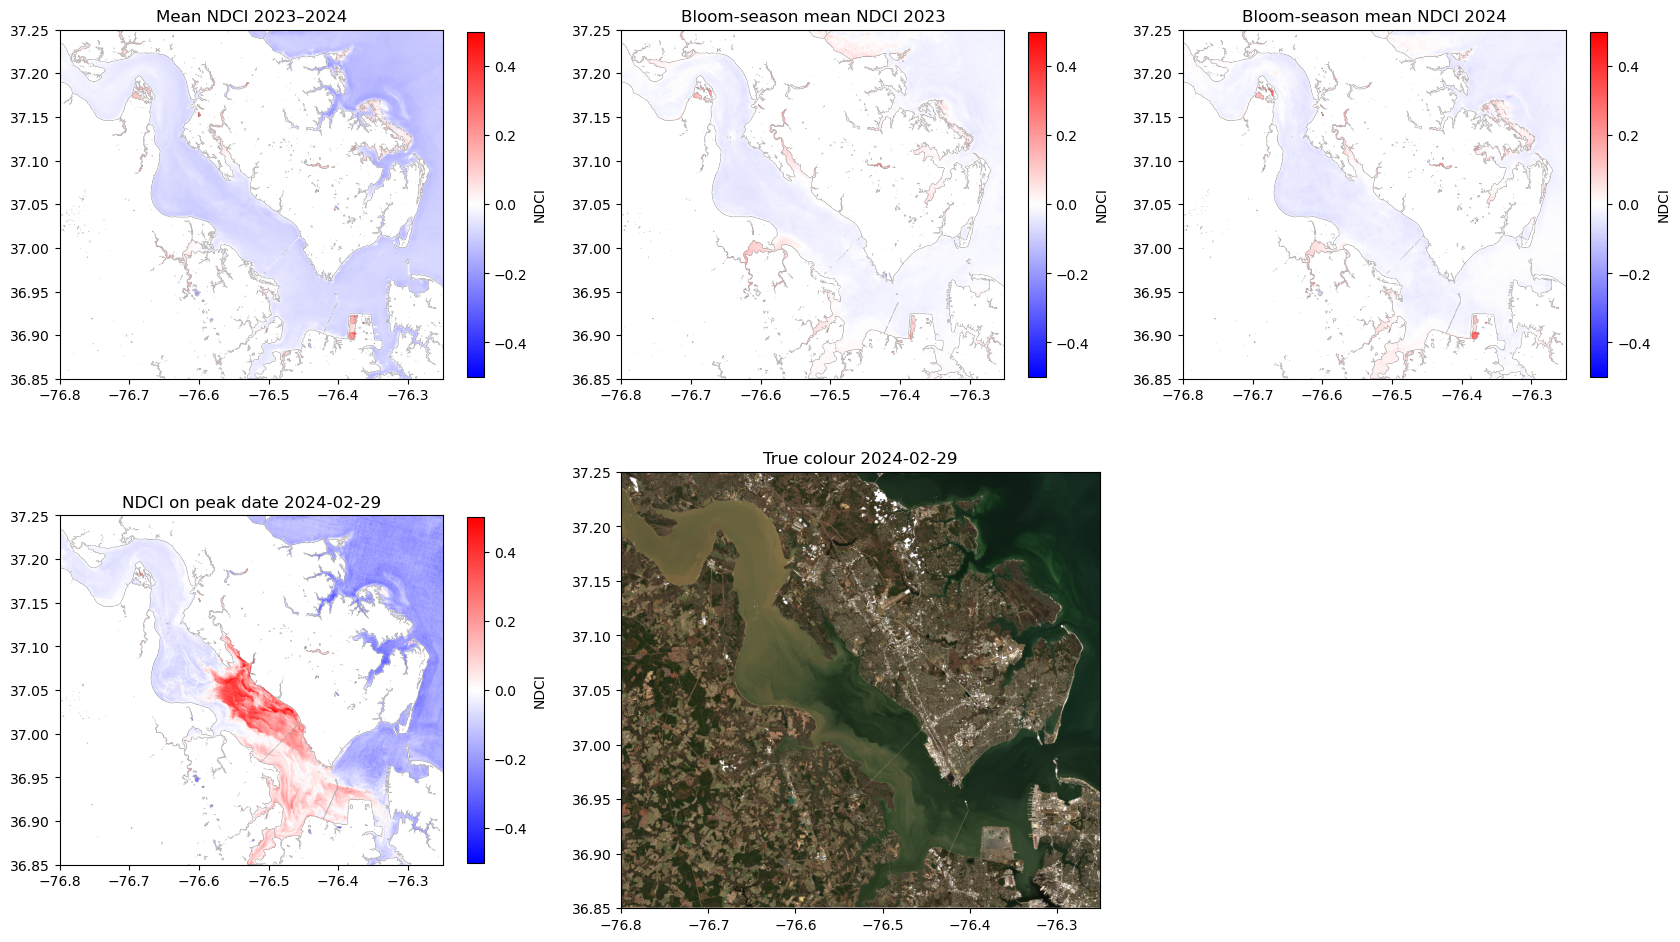

In [9]:
MAP_DIR = f"{OUT_DIR}/map_images"
os.makedirs(MAP_DIR, exist_ok=True)
NDCI_PAL = ["blue", "white", "red"]                   # as in the original script

def thumb(key, vis_image):
    # Render a map once and save it; later runs load the saved image
    path = f"{MAP_DIR}/{key}.png"
    if os.path.exists(path) and not FORCE_RECOMPUTE:
        return np.array(Image.open(path))
    for dims in (1200, 900, 600):
        try:
            url = vis_image.clip(roi).getThumbURL({"region": roi, "dimensions": dims, "crs": "EPSG:4326", "format": "png"})
            resp = requests.get(url, timeout=600); resp.raise_for_status()
            img = Image.open(io.BytesIO(resp.content)); img.save(path)
            return np.array(img)
        except Exception as e:
            print(f"  {key} at {dims}px failed ({str(e)[:60]}), trying smaller")
    raise RuntimeError(f"Could not render map {key}")

def ndci_vis(img):
    return img.select("ndci").visualize(min=-0.5, max=0.5, palette=NDCI_PAL)

def rgb_vis(collection):
    def mask_s2(im):
        scl = im.select("SCL")
        clear = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
        return im.select(["B4", "B3", "B2"]).multiply(0.0001).updateMask(clear)
    return collection.map(mask_s2).median().visualize(min=0, max=0.25, gamma=1.2)

years = sorted(set(good.index.year))
panels = [(thumb("ndci_mean_period", ndci_vis(indices.mean())), f"Mean NDCI {START[:4]}–{years[-1]}", True)]
for y in years:
    season = indices.filterDate(f"{y}-{BLOOM_MONTHS[0]:02d}-01", f"{y}-{BLOOM_MONTHS[-1] + 1:02d}-01")
    panels.append((thumb(f"ndci_bloom_season_{y}", ndci_vis(season.mean())), f"Bloom-season mean NDCI {y}", True))
peak_col = s2.filterDate(f"{peak_date:%Y-%m-%d}", f"{peak_date + pd.Timedelta(days=1):%Y-%m-%d}")
panels.append((thumb(f"ndci_peak_{peak_date:%Y%m%d}", ndci_vis(peak_col.map(prepare).mosaic())),
               f"NDCI on peak date {peak_date:%Y-%m-%d}", True))
panels.append((thumb(f"rgb_peak_{peak_date:%Y%m%d}", rgb_vis(peak_col)), f"True colour {peak_date:%Y-%m-%d}", False))

extent = [BBOX[0], BBOX[2], BBOX[1], BBOX[3]]
ncol = 3
nrow = int(np.ceil(len(panels) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(17, 5 * nrow))
for ax, (arr, title, with_bar) in zip(np.ravel(axes), panels):
    ax.imshow(arr, extent=extent)
    ax.set_title(title); ax.set_aspect(1 / np.cos(np.deg2rad(np.mean(BBOX[1::2]))))
    if with_bar:
        sm = plt.cm.ScalarMappable(cmap=LinearSegmentedColormap.from_list("ndci", NDCI_PAL), norm=Normalize(-0.5, 0.5))
        fig.colorbar(sm, ax=ax, label="NDCI", shrink=0.75)
for ax in np.ravel(axes)[len(panels):]:
    ax.axis("off")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/03_ndci_maps.png"); plt.show()

## 8. Notes

- **Data:** Copernicus Sentinel-2 Level-2A (harmonized); JRC Global Surface Water v1.4 (Pekel et al. 2016).
- **NDCI** and the chlorophyll-a conversion follow Mishra & Mishra (2012). The conversion was calibrated on other
  waters, so the µg/L values are indicative only; NDCI and the bloom fraction are best used for relative comparisons
  between dates, years and parts of the lake.
- High NDCI can also come from floating vegetation, shallow water or turbid shorelines; in-situ samples are needed
  for absolute chlorophyll concentrations or toxin assessment.
- Dates where less than `MIN_COVERAGE` of the lake is cloud-free are excluded from the statistics.
- To study another lake, change `BBOX` and `ROI_NAME` and set `FORCE_RECOMPUTE = True` once.